# Foundation transfer

Probe how well the `Bat_Transformer` trajectory branch generalizes across sessions, bats, and environments.

For each held-out group we train three models and compare test FDE:
1. **Foundation** — trained on all source (non-held-out) sessions.
2. **Finetune** — foundation weights frozen, only the target readout is fine-tuned on the held-out data.
3. **Scratch** — a fresh model trained end-to-end on only the held-out data.

Five sweeps: 18-fold session, 14-fold session (Datasets 1+3 only), 6-fold bat, 4-fold bat (D1+D3), environment (D1+D3 → D2).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import glob
import pickle
import threading
import traceback
from concurrent.futures import ThreadPoolExecutor, as_completed
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.layers import ELU1
from digitalbat.training.trainer import bat_former_trainer, finetune_readout_trainer
from digitalbat.utility.utils import set_random_state, poisson_fde_population, corr


In [ ]:
SEED = 1
WD = 0.1
DEVICE = 'cuda'

# Training budget (see plan: user chose smoke-test sizing)
N_EPOCHS_FOUNDATION = 1000
N_EPOCHS_FINETUNE = 1000
N_EPOCHS_SCRATCH = 1000
EARLY_STOP_PATIENCE = 100
LR = 1e-2

# Parallel-within-GPU training. Tune based on `nvidia-smi` VRAM headroom.
MAX_WORKERS = 32

OUT_ROOT = os.path.abspath('./out/transfer')
os.makedirs(OUT_ROOT, exist_ok=True)

set_random_state(SEED)

# Dataloader (all 18 sessions)

In [3]:
data_config = dict(
    use_speed_head_dir = False,
    use_IMU_flag = False,
    use_click_flag = False,
    use_LFP_flag = False,
    use_ripple_flag = False,
    only_flight_flag = True,
    firing_rate_criterion_flag = True,
    max_acceleration = 50,
    no_3d_location = False,
    spike_count_flag = True,
    bin_width = 0.10,
    split_flights_for_train = 'random',
    type_train_num = 1,
    type_valid_num = 1,
    special_id_count_thresh = 3,
    only_use_special_id_4train_flag = False,
    shuffle_flag = True,
    time_shuffle_for_trajecotry_flag = False,
    simulate_place_cell_flag = False,
    split_each_trajectory_flag = True,
    window_size = None,
    stride_train = None,
    stride_test = None,
    batch_size_train = None,
    batch_size_test = None,
    session_names = [
        'Dataset_3_14543_240419',
        'Dataset_3_14543_240420',
        'Dataset_3_14543_240421',
        'Dataset_3_29959_240402',
        'Dataset_3_29959_240403',
        'Dataset_3_29959_240404',
        'Dataset_2_14445_231208',
        'Dataset_2_14445_231209',
        'Dataset_1_32622_231009',
        'Dataset_1_32622_231010',
        'Dataset_1_32622_231007',
        'Dataset_2_14611_231208',
        'Dataset_2_14611_231209',
        'Dataset_3_00000_240402',
        'Dataset_3_00000_240403',
        'Dataset_3_00000_240404',
        'Dataset_3_00000_240405',
        'Dataset_3_29959_240405',
    ],
    parent_folder = '/mnt/s5/Adam/Angelo/NP_datasets/',
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'Loaded {len(unit_num_dict)} sessions, behavior_dim={behavior_dim}')
print(f'Units per session: {unit_num_dict}')

  Acceleration filter: removed 1/37 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
Loaded 18 sessions, behavior_dim=3
Units per session: {'Dataset_3_14543_240419': 204, 'Dataset_3_14543_240420': 77, 'Dataset_3_14543_240421': 65, 'Dataset_3_29959_240402': 266, 'Dataset_3_29959_240403': 149, 'Dataset_3_29959_240404': 121, 'Dataset_2_14445_231208': 155, 'Dataset_2_14445_231209': 102, 'Dataset_1_32622_231009':

# Experiment bookkeeping

In [4]:
SESSIONS = list(unit_num_dict)

def dataset_of(session_name):
    # 'Dataset_{N}_...' -> 'D{N}'
    return 'D' + session_name.split('_')[1]

def bat_of(session_name):
    # 'Dataset_{N}_{bat_id}_{date}'
    return session_name.split('_')[2]

SESSIONS_D13 = [s for s in SESSIONS if dataset_of(s) != 'D2']
SESSIONS_D2  = [s for s in SESSIONS if dataset_of(s) == 'D2']

BATS = sorted({bat_of(s) for s in SESSIONS})
BATS_D13 = sorted({bat_of(s) for s in SESSIONS_D13})

print(f'All sessions ({len(SESSIONS)}): {SESSIONS}')
print(f'D1+D3 sessions ({len(SESSIONS_D13)}): {SESSIONS_D13}')
print(f'D2 sessions ({len(SESSIONS_D2)}): {SESSIONS_D2}')
print(f'Bats ({len(BATS)}): {BATS}')
print(f'Bats D1+D3 ({len(BATS_D13)}): {BATS_D13}')

All sessions (18): ['Dataset_3_14543_240419', 'Dataset_3_14543_240420', 'Dataset_3_14543_240421', 'Dataset_3_29959_240402', 'Dataset_3_29959_240403', 'Dataset_3_29959_240404', 'Dataset_2_14445_231208', 'Dataset_2_14445_231209', 'Dataset_1_32622_231009', 'Dataset_1_32622_231010', 'Dataset_1_32622_231007', 'Dataset_2_14611_231208', 'Dataset_2_14611_231209', 'Dataset_3_00000_240402', 'Dataset_3_00000_240403', 'Dataset_3_00000_240404', 'Dataset_3_00000_240405', 'Dataset_3_29959_240405']
D1+D3 sessions (14): ['Dataset_3_14543_240419', 'Dataset_3_14543_240420', 'Dataset_3_14543_240421', 'Dataset_3_29959_240402', 'Dataset_3_29959_240403', 'Dataset_3_29959_240404', 'Dataset_1_32622_231009', 'Dataset_1_32622_231010', 'Dataset_1_32622_231007', 'Dataset_3_00000_240402', 'Dataset_3_00000_240403', 'Dataset_3_00000_240404', 'Dataset_3_00000_240405', 'Dataset_3_29959_240405']
D2 sessions (4): ['Dataset_2_14445_231208', 'Dataset_2_14445_231209', 'Dataset_2_14611_231208', 'Dataset_2_14611_231209']
Bats

# Helpers

In [5]:
def filter_dataloaders(dataloaders, keep_sessions):
    """Return a new train/valid/test dict restricted to `keep_sessions` (preserving order)."""
    keep = list(keep_sessions)
    return {
        split: {s: dataloaders[split][s] for s in keep if s in dataloaders[split]}
        for split in ('train', 'valid', 'test')
    }


MODEL_CONFIG_BASE = dict(
    use_place_as_input=False,
    use_trajectory_as_input=True,
    latent_dim=32,
    ff_dim=32,
    num_heads=4,
    num_layers=1,
    dropout_prob=0.3,
    final_activation=ELU1(),
)

def build_bat_former(unit_num_sub, behavior_dim, seed=SEED):
    """Fresh Bat_Transformer with readouts sized for sessions in `unit_num_sub`."""
    set_random_state(seed)
    return Bat_Transformer(
        input_dim=behavior_dim,
        output_dim_dict=unit_num_sub,
        **MODEL_CONFIG_BASE,
    )


def freeze_core_for_finetune(model, target_session):
    """Freeze transformer core and all non-target readouts; keep readouts[target_session] trainable."""
    for p in model.parameters():
        p.requires_grad = False
    for p in model.readouts[target_session].parameters():
        p.requires_grad = True
    # sanity check
    n_train = sum(p.requires_grad for p in model.parameters())
    n_target = sum(p.requires_grad for p in model.readouts[target_session].parameters())
    assert n_train == n_target, f'freeze mismatch: {n_train} != {n_target}'
    return model

In [6]:
def ckpt_path(group, heldout, suffix=''):
    """./out/transfer/{group}/bat_former_seed_{SEED}_wd_{WD}_by_{group}_held_{heldout}{suffix}.pth"""
    d = os.path.join(OUT_ROOT, group)
    os.makedirs(d, exist_ok=True)
    name = f'bat_former_seed_{SEED}_wd_{WD}_by_{group}_held_{heldout}{suffix}.pth'
    return os.path.join(d, name)


def eval_on_session(model, session, dataloaders, split='test'):
    """Return per-neuron FDE and mean corr on the given session/split."""
    model = model.to(DEVICE)
    model.eval()
    y_true_list, y_pred_list = [], []
    with torch.no_grad():
        for batch in dataloaders[split][session]:
            X = batch.behavior.to(DEVICE)
            mask = batch.mask.to(DEVICE)
            y = batch.spike.to(DEVICE)
            y_pred = model(session, X, mask)
            y_true_list.append(y.detach()[mask == 1.0].cpu().numpy())
            y_pred_list.append(y_pred.detach()[mask == 1.0].cpu().numpy())
    y_true = np.vstack(y_true_list)
    y_pred = np.vstack(y_pred_list)
    fde = poisson_fde_population(y_true, y_pred)
    pc = corr(y_true, y_pred, axis=0)
    return fde, pc

# Parallel-within-GPU runner

A ThreadPoolExecutor shares one CUDA context; distinct `nn.Module` instances don't race on each other's parameters. We give each worker its own `torch.cuda.Stream` so kernels interleave instead of serializing on the default stream. If VRAM is tight, lower `MAX_WORKERS`: tasks that OOM get retried serially at the end.

In [7]:
def _run_on_stream(fn):
    stream = torch.cuda.Stream()
    with torch.cuda.stream(stream):
        out = fn()
    stream.synchronize()
    return out


def run_tasks_parallel(tasks, max_workers=MAX_WORKERS, label=''):
    """
    tasks: list of (task_id, callable_no_args) tuples.
    Returns: {task_id: result}. OOM failures are retried serially after the parallel wave.
    """
    results = {}
    oom_retries = []

    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        futs = {pool.submit(_run_on_stream, fn): tid for tid, fn in tasks}
        for fut in as_completed(futs):
            tid = futs[fut]
            try:
                results[tid] = fut.result()
                print(f'[{label}] done: {tid}')
            except torch.cuda.OutOfMemoryError:
                print(f'[{label}] OOM on {tid}, will retry serially')
                oom_retries.append(tid)
            except Exception as e:
                print(f'[{label}] {tid} FAILED: {type(e).__name__}: {e}')
                traceback.print_exc()
                results[tid] = None

    if oom_retries:
        torch.cuda.empty_cache()
        tid_to_fn = dict(tasks)
        for tid in oom_retries:
            try:
                print(f'[{label}] serial retry: {tid}')
                results[tid] = tid_to_fn[tid]()
            except Exception as e:
                print(f'[{label}] {tid} FAILED (serial): {e}')
                results[tid] = None
    return results

# Single-fold training primitives

In [8]:
def train_foundation(source_sessions, save_path, seed=SEED):
    """Train Bat_Transformer end-to-end on `source_sessions`, save state_dict, return (best_score, model)."""
    unit_sub = {s: unit_num_dict[s] for s in source_sessions}
    model = build_bat_former(unit_sub, behavior_dim, seed=seed)
    dl_sub = filter_dataloaders(dataloaders, source_sessions)
    cfg = dict(
        model=model,
        dataloaders=dl_sub,
        device=DEVICE,
        n_epochs=N_EPOCHS_FOUNDATION,
        lr=LR,
        weight_decay=WD,
        loss_fn=nn.PoissonNLLLoss(log_input=False),
        valid_fn=poisson_fde_population,
        valid_stat='median',
        early_stopping_patience=EARLY_STOP_PATIENCE,
        save_model=True,
        model_name=save_path,
    )
    best_score, _, _ = bat_former_trainer(**cfg)
    return best_score, model


def train_scratch(target_session, save_path, seed=SEED):
    """Train Bat_Transformer from scratch on a single target session."""
    unit_sub = {target_session: unit_num_dict[target_session]}
    model = build_bat_former(unit_sub, behavior_dim, seed=seed)
    dl_sub = filter_dataloaders(dataloaders, [target_session])
    cfg = dict(
        model=model,
        dataloaders=dl_sub,
        device=DEVICE,
        n_epochs=N_EPOCHS_SCRATCH,
        lr=LR,
        weight_decay=WD,
        loss_fn=nn.PoissonNLLLoss(log_input=False),
        valid_fn=poisson_fde_population,
        valid_stat='median',
        early_stopping_patience=EARLY_STOP_PATIENCE,
        save_model=True,
        model_name=save_path,
    )
    best_score, _, _ = bat_former_trainer(**cfg)
    return best_score, model


def finetune_from(foundation_path, source_sessions, target_session, save_path, seed=SEED):
    """
    Load foundation weights, add a fresh readout for `target_session`, freeze the core,
    and fine-tune only that readout using `finetune_readout_trainer`.
    """
    # Build a model whose readouts cover both source and target sessions so the foundation
    # state_dict loads cleanly.
    all_sessions = list(source_sessions) + [target_session]
    unit_sub = {s: unit_num_dict[s] for s in all_sessions}
    model = build_bat_former(unit_sub, behavior_dim, seed=seed)

    state = torch.load(foundation_path, map_location=DEVICE)
    # Only the source readouts + core are in the foundation; the target readout is fresh.
    missing_ok = {f'readouts.{target_session}.' }
    filtered = {k: v for k, v in state.items() if not any(k.startswith(p) for p in missing_ok)}
    msg = model.load_state_dict(filtered, strict=False)
    # Missing keys should be *only* the target readout.
    unexpected = [k for k in msg.unexpected_keys]
    target_missing = [k for k in msg.missing_keys if k.startswith(f'readouts.{target_session}.')]
    other_missing = [k for k in msg.missing_keys if not k.startswith(f'readouts.{target_session}.')]
    assert not unexpected, f'unexpected keys: {unexpected}'
    assert not other_missing, f'unexpected missing keys: {other_missing}'
    assert target_missing, f'expected target readout to be fresh'

    freeze_core_for_finetune(model, target_session)
    dl_sub = filter_dataloaders(dataloaders, [target_session])  # only the target session
    cfg = dict(
        model=model,
        dataloaders=dl_sub,
        device=DEVICE,
        target_session=target_session,
        n_epochs=N_EPOCHS_FINETUNE,
        lr=LR,
        weight_decay=WD,
        loss_fn=nn.PoissonNLLLoss(log_input=False),
        valid_fn=poisson_fde_population,
        valid_stat='median',
        early_stopping_patience=EARLY_STOP_PATIENCE,
        save_model=True,
        model_name=save_path,
    )
    best_score, _, _ = finetune_readout_trainer(**cfg)
    return best_score, model

In [9]:
def _record_eval(rows, model, target_session, group, heldout, mode):
    fde, pc = eval_on_session(model, target_session, dataloaders, split='test')
    for i, (f, c) in enumerate(zip(fde, pc)):
        rows.append(dict(group=group, heldout=heldout, target_session=target_session,
                         neuron_idx=i, mode=mode, fde=float(f), corr=float(c)))


def run_transfer_sweep(group_name, held_groups, universe_sessions,
                        session_membership_fn, max_workers=MAX_WORKERS):
    """
    Run a three-way (foundation / finetune / scratch) sweep over `held_groups`.
    universe_sessions: full pool the experiment draws from (e.g. SESSIONS or SESSIONS_D13).
    session_membership_fn(heldout) -> list of target session names for that held-out group.
    """
    rows = []
    universe = list(universe_sessions)

    # ---- Wave 1: foundations + scratches in parallel ----
    wave1 = []
    for heldout in held_groups:
        target = session_membership_fn(heldout)
        source = [s for s in universe if s not in target]
        f_path = ckpt_path(group_name, heldout)
        wave1.append((f'FND:{heldout}',
                      lambda src=source, p=f_path: train_foundation(src, p)))
        for t in target:
            s_path = ckpt_path(group_name, heldout, suffix=f'__{t}_scratch')
            wave1.append((f'SCR:{heldout}:{t}',
                          lambda t=t, p=s_path: train_scratch(t, p)))

    res1 = run_tasks_parallel(wave1, max_workers=max_workers, label=f'{group_name}-wave1')

    # evaluate scratches now (model still on GPU inside result)
    for heldout in held_groups:
        for t in session_membership_fn(heldout):
            r = res1.get(f'SCR:{heldout}:{t}')
            if r is None:
                continue
            _, m = r
            _record_eval(rows, m, t, group_name, heldout, mode='scratch')

    # ---- Wave 2: finetunes (each loads the matching foundation .pth) ----
    wave2 = []
    for heldout in held_groups:
        target = session_membership_fn(heldout)
        source = [s for s in universe if s not in target]
        f_path = ckpt_path(group_name, heldout)
        for t in target:
            ft_path = ckpt_path(group_name, heldout, suffix=f'__{t}_finetune')
            wave2.append((f'FT:{heldout}:{t}',
                          lambda src=source, t=t, fp=f_path, p=ft_path: finetune_from(fp, src, t, p)))

    res2 = run_tasks_parallel(wave2, max_workers=max_workers, label=f'{group_name}-wave2')
    for heldout in held_groups:
        for t in session_membership_fn(heldout):
            r = res2.get(f'FT:{heldout}:{t}')
            if r is None:
                continue
            _, m = r
            _record_eval(rows, m, t, group_name, heldout, mode='finetune')

    df = pd.DataFrame(rows)
    df_path = os.path.join(OUT_ROOT, group_name, f'results_{group_name}.pkl')
    df.to_pickle(df_path)
    print(f'Saved {len(df)} rows to {df_path}')
    return df

# Experiment 3: environment transfer

Train on Datasets 1+3, fine-tune on Dataset 2. This is the smallest sweep (one fold) and runs first to validate the pipeline.

In [16]:
RUN_ENV = True

if RUN_ENV:
    df_env = run_transfer_sweep(
        group_name='env',
        held_groups=['D2'],
        universe_sessions=SESSIONS,
        session_membership_fn=lambda _: SESSIONS_D2,
    )
    df_env.groupby('mode')['fde'].describe()

Training:   0%|          | 0/1000 [00:00<?, ?it/s]







Training:   0%|          | 2/1000 [00:00<01:01, 16.19it/s]


Training:   0%|          | 4/1000 [00:00<00:58, 17.01it/s]


Training:   1%|          | 10/1000 [00:00<01:07, 14.77it/s]


Training:   1%|          | 12/1000 [00:00<01:03, 15.59it/s]


Training:   2%|▏         | 16/1000 [00:00<00:50, 19.30it/s]




Training:   2%|▏         | 19/1000 [00:01<00:50, 19.57it/s]





Training:   2%|▏         | 22/1000 [00:01<00:47, 20.40it/s]


Training:   2%|▎         | 25/1000 [00:01<00:46, 20.95it/s]


Training:   3%|▎         | 28/1000 [00:01<00:43, 22.23it/s]


Training:   3%|▎         | 31/1000 [00:01<00:44, 21.69it/s]


Training:   4%|▎         | 37/1000 [00:01<00:42, 22.48it/s]


Training:   4%|▍         | 40/1000 [00:01<00:43, 22.09it/s]


Training:   4%|▍         | 43/1000 [00:02<00:45, 21.13it/s]






Training:   5%|▍         | 46/1000 [00:02<00:45, 20.96it/s]


Training:   5%|▍         | 49/1000 [00:02<00:44, 21.48it/s]


Train

Early stopping at epoch 203 (no improvement for 100 epochs)
[env-wave1] done: SCR:D2:Dataset_2_14611_231209





Training:  23%|██▎       | 229/1000 [00:10<00:31, 24.85it/s]





Training:  23%|██▎       | 232/1000 [00:10<00:30, 25.58it/s]


Training:  24%|██▎       | 235/1000 [00:11<00:28, 26.53it/s]


Training:  24%|██▍       | 240/1000 [00:11<00:24, 30.41it/s]


Training:  24%|██▍       | 244/1000 [00:11<00:25, 29.43it/s]


Training:  25%|██▍       | 247/1000 [00:11<00:27, 27.79it/s]





Training:  25%|██▌       | 250/1000 [00:11<00:28, 26.08it/s]



Training:  25%|██▌       | 254/1000 [00:11<00:27, 27.21it/s]


Training:  26%|██▌       | 258/1000 [00:11<00:35, 20.77it/s]


Training:  26%|██▌       | 262/1000 [00:12<00:30, 24.34it/s]

Training:  27%|██▋       | 266/1000 [00:12<00:26, 27.20it/s]



Training:  27%|██▋       | 270/1000 [00:12<00:28, 26.06it/s]





Training:  27%|██▋       | 273/1000 [00:12<00:27, 26.39it/s]




Training:  28%|██▊       | 277/1000 [00:12<00:26, 27.47it/s]


Training:  28%|██▊       | 281/1000 [00:12<00:24, 29.07it/s]


Training:  28%|██▊       | 285/1000 [00:

Early stopping at epoch 322 (no improvement for 100 epochs)
[env-wave1] done: SCR:D2:Dataset_2_14611_231208



















































































































































































































































Training:  62%|██████▏   | 624/1000 [00:22<00:13, 27.64it/s]



...

Early stopping at epoch 258 (no improvement for 100 epochs)
[env-wave2] done: FT:D2:Dataset_2_14445_231208






Finetune[Dataset_2_14611_231209]:  30%|███       | 300/1000 [00:10<00:24, 28.50it/s]




Early stopping at epoch 301 (no improvement for 100 epochs)
[env-wave2] done: FT:D2:Dataset_2_14611_231209






Finetune[Dataset_2_14445_231209]:  37%|███▋      | 373/1000 [00:11<00:19, 32.82it/s] 


Early stopping at epoch 374 (no improvement for 100 epochs)
[env-wave2] done: FT:D2:Dataset_2_14445_231209
Saved 1116 rows to /home/alowet/Documents/code/digitalbat/notebooks/out/transfer/env/results_env.pkl


# Experiment 1a: 18-fold session transfer

In [10]:
RUN_SESSION_18 = True  # long: 18 foundations + 18 scratches + 18 finetunes

if RUN_SESSION_18:
    df_session = run_transfer_sweep(
        group_name='session',
        held_groups=SESSIONS,
        universe_sessions=SESSIONS,
        session_membership_fn=lambda s: [s],
    )

Training:   0%|          | 0/1000 [00:00<?, ?it/s]




















































































































Training:   0%|          | 1/1000 [00:00<08:21,  1.99it/s]




Training:   0%|          | 2/1000 [00:00<04:36,  3.61it/s]



























Training:   0%|          | 3/1000 [00:00<03:39,  4.54it/s]

































Training:   0%|          | 5/1000 [00:01<02:41,  6.14it/s]






























Training:   1%|          | 7/1000 [00:01<02:54,  5.70it/s]



















Training:   1%|          | 9/1000 [00:01<02:24,  6.85it/s]
















Training:   1%|          | 10/1000 [00:01<02:23,  6.88it/s]













Training:   1%|          | 11/1000 [00:01<02:20,  7.04it/s]



























Training:   1%|          | 12/1000 [00:02<02:18,  7.11it/s]












Training:   1%|▏         | 13/1000 [00:02<02:15,  7.26it/s]









Training:   1%|▏         | 14/1000 [00:02<02:10, 

Early stopping at epoch 208 (no improvement for 100 epochs)
[session-wave1] done: SCR:Dataset_3_14543_240419:Dataset_3_14543_240419











Training:  16%|█▌        | 162/1000 [00:28<02:28,  5.64it/s]
































Training:  16%|█▋        | 163/1000 [00:28<02:24,  5.79it/s]



Training:  16%|█▋        | 164/1000 [00:28<02:48,  4.97it/s]













Training:  16%|█▋        | 165/1000 [00:28<02:35,  5.37it/s]



























Training:  17%|█▋        | 166/1000 [00:29<02:21,  5.89it/s]









Training:  17%|█▋        | 167/1000 [00:29<02:19,  5.99it/s]












Training:  17%|█▋        | 168/1000 [00:29<02:07,  6.50it/s]














Training:  17%|█▋        | 169/1000 [00:29<02:03,  6.74it/s]













Training:  17%|█▋        | 170/1000 [00:29<02:09,  6.42it/s]













Training:  17%|█▋        | 171/1000 [00:29<02:52,  4.80it/s]












Training:  17%|█▋        | 172/1000 [00:30<02:44,  5.05it/s]





















Training:  17%|█▋        | 173/1000 [00:30<02:32,  5.42it/s]





















Training:  17%|█▋        | 174/1000 [00:30<02:24,  5.71it/s]










Early stopping at epoch 395 (no improvement for 100 epochs)
[session-wave1] done: SCR:Dataset_2_14445_231208:Dataset_2_14445_231208


Training:  39%|███▉      | 394/1000 [01:08<01:25,  7.13it/s]























Training:  40%|███▉      | 395/1000 [01:08<01:25,  7.07it/s]













Training:  40%|███▉      | 396/1000 [01:08<02:00,  5.00it/s]













Training:  40%|███▉      | 397/1000 [01:08<01:53,  5.32it/s]





















Training:  40%|███▉      | 398/1000 [01:08<01:47,  5.60it/s]












Training:  40%|███▉      | 399/1000 [01:09<01:42,  5.84it/s]









Training:  40%|████      | 400/1000 [01:09<01:34,  6.34it/s]















Training:  40%|████      | 401/1000 [01:09<01:32,  6.47it/s]





















Training:  40%|████      | 402/1000 [01:09<01:29,  6.69it/s]












Training:  40%|████      | 403/1000 [01:09<01:28,  6.73it/s]






Training:  40%|████      | 404/1000 [01:09<02:01,  4.89it/s]









Training:  40%|████      | 405/1000 [01:10<01:46,  5.59it/s]

























Training:  41%|████      | 406/1000 [01:10<01:42,  5.79it/s]













Training:  41%|

...

[session-wave2] done: FT:Dataset_3_00000_240403:Dataset_3_00000_240403
Early stopping at epoch 296 (no improvement for 100 epochs)
[session-wave2] done: FT:Dataset_3_29959_240402:Dataset_3_29959_240402














































































































































































































Finetune[Dataset_3_14543_240420]: 100%|██████████| 1000/1000 [02:29<00:00,  6.70it/s]


























[session-wave2] done: FT:Dataset_3_14543_240420:Dataset_3_14543_240420










































































































































































































































































Finetune[Dataset_3_00000_240405]:  86%|████████▌ | 860/1000 [01:55<00:18,  7.46it/s] 

Early stopping at epoch 861 (no improvement for 100 epochs)
[session-wave2] done: FT:Dataset_3_00000_240405:Dataset_3_00000_240405
Saved 4506 rows to /home/alowet/Documents/code/digitalbat/notebooks/out/transfer/session/results_session.pkl


# Experiment 1b: 14-fold session transfer (Datasets 1+3 only)

In [ ]:
RUN_SESSION_14 = False

if RUN_SESSION_14:
    df_session_d13 = run_transfer_sweep(
        group_name='session_d13',
        held_groups=SESSIONS_D13,
        universe_sessions=SESSIONS_D13,
        session_membership_fn=lambda s: [s],
    )

Training:   0%|          | 0/1000 [00:00<?, ?it/s]


Training:   2%|▏         | 18/1000 [00:00<00:40, 24.02it/s]


Training:   4%|▎         | 37/1000 [00:01<00:44, 21.64it/s]

Training:   5%|▌         | 52/1000 [00:02<00:40, 23.61it/s]

Training:   7%|▋         | 70/1000 [00:02<00:39, 23.38it/s]

Training:   8%|▊         | 83/1000 [00:03<00:36, 25.12it/s]

Training:  10%|█         | 100/1000 [00:04<00:35, 25.49it/s]


Training:  12%|█▏        | 117/1000 [00:04<00:34, 25.93it/s]

Training:  13%|█▎        | 133/1000 [00:05<00:33, 25.61it/s]

Training:  15%|█▌        | 151/1000 [00:06<00:37, 22.80it/s]

Training:  17%|█▋        | 168/1000 [00:06<00:33, 25.19it/s]

Training:  18%|█▊        | 184/1000 [00:07<00:33, 24.54it/s]

Training:  21%|██        | 212/1000 [00:07<00:28, 27.96it/s]


Early stopping at epoch 213 (no improvement for 100 epochs)
[session_d13-wave1] done: SCR:Dataset_3_14543_240419:Dataset_3_14543_240419


Training:  20%|██        | 205/1000 [00:08<00:31, 25.01it/s]

Training:  22%|██▏       | 218/1000 [00:08<00:31, 24.90it/s]

Training:  24%|██▎       | 237/1000 [00:09<00:28, 27.05it/s]

Training:  25%|██▌       | 253/1000 [00:10<00:29, 25.67it/s]

Training:  26%|██▋       | 265/1000 [00:10<00:31, 23.56it/s]

Training:  28%|██▊       | 281/1000 [00:11<00:27, 25.78it/s]

Training:  30%|██▉       | 296/1000 [00:11<00:29, 23.99it/s]

Training:  32%|███▏      | 315/1000 [00:12<00:26, 26.11it/s]

Training:  33%|███▎      | 334/1000 [00:13<00:30, 21.70it/s]

Training:  35%|███▍      | 348/1000 [00:13<00:23, 27.89it/s]

Training:  37%|███▋      | 366/1000 [00:14<00:23, 26.86it/s]

Training:  38%|███▊      | 384/1000 [00:15<00:29, 21.10it/s]


Training:  40%|████      | 403/1000 [00:16<00:22, 26.07it/s]

Training:  42%|████▏     | 420/1000 [00:16<00:22, 25.32it/s]

Training:  44%|████▍     | 440/1000 [00:17<00:21, 26.04it/s]

Training:  46%|████▌     | 456/1000 [00:18<00:21, 25.80it/s]

Trainin

Early stopping at epoch 595 (no improvement for 100 epochs)
[session_d13-wave1] done: SCR:Dataset_3_14543_240420:Dataset_3_14543_240420


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Training:   2%|▏         | 17/1000 [00:00<00:30, 32.09it/s]

Training:   3%|▎         | 34/1000 [00:01<00:41, 23.42it/s]

Training:   5%|▌         | 52/1000 [00:01<00:32, 29.47it/s]

Training:   7%|▋         | 72/1000 [00:02<00:30, 30.12it/s]

Training:  10%|▉         | 95/1000 [00:03<00:31, 28.64it/s]


Training:  12%|█▏        | 116/1000 [00:04<00:30, 28.96it/s]


Training:  14%|█▎        | 135/1000 [00:04<00:27, 31.40it/s]


Training:  16%|█▌        | 156/1000 [00:05<00:25, 32.68it/s]


Training:  18%|█▊        | 176/1000 [00:05<00:27, 29.51it/s]


Training:  19%|█▉        | 191/1000 [00:06<00:27, 29.78it/s]


...

Early stopping at epoch 595 (no improvement for 100 epochs)
[session_d13-wave2] done: FT:Dataset_3_00000_240402:Dataset_3_00000_240402










































































































Finetune[Dataset_3_29959_240405]:  49%|████▉     | 491/1000 [00:09<00:10, 50.59it/s]






Early stopping at epoch 492 (no improvement for 100 epochs)
[session_d13-wave2] done: FT:Dataset_3_29959_240405:Dataset_3_29959_240405






































































Finetune[Dataset_3_00000_240405]:  88%|████████▊ | 877/1000 [00:27<00:03, 32.19it/s] 


Early stopping at epoch 878 (no improvement for 100 epochs)
[session_d13-wave2] done: FT:Dataset_3_00000_240405:Dataset_3_00000_240405
Saved 3390 rows to /home/alowet/Documents/code/digitalbat/notebooks/out/transfer/session_d13/results_session_d13.pkl


# Experiment 2a: 6-fold bat transfer

In [11]:
RUN_BAT_6 = True

if RUN_BAT_6:
    df_bat = run_transfer_sweep(
        group_name='bat',
        held_groups=BATS,
        universe_sessions=SESSIONS,
        session_membership_fn=lambda b: [s for s in SESSIONS if bat_of(s) == b],
    )

Training:   0%|          | 0/1000 [00:00<?, ?it/s]


































































































































Training:   0%|          | 1/1000 [00:00<03:19,  5.00it/s]




































































Training:   0%|          | 2/1000 [00:00<03:12,  5.18it/s]



















Training:   0%|          | 3/1000 [00:00<02:51,  5.80it/s]












































Training:   0%|          | 4/1000 [00:00<03:39,  4.53it/s]




















































Training:   1%|          | 6/1000 [00:01<02:34,  6.42it/s]

















































Training:   1%|          | 7/1000 [00:01<02:33,  6.47it/s]
















Training:   1%|          | 8/1000 [00:01<02:22,  6.96it/s]












































Training:   1%|          | 9/1000 [00:01<02:25,  6.82it/s]
































Training:   1%|        

Early stopping at epoch 164 (no improvement for 100 epochs)
[bat-wave1] done: SCR:14543:Dataset_3_14543_240419





























Training:  13%|█▎        | 128/1000 [00:22<02:25,  5.99it/s]






























Training:  13%|█▎        | 129/1000 [00:23<02:19,  6.23it/s]





















































Training:  13%|█▎        | 130/1000 [00:23<02:19,  6.24it/s]





































Training:  13%|█▎        | 131/1000 [00:23<02:55,  4.94it/s]

















































Training:  13%|█▎        | 132/1000 [00:23<02:46,  5.21it/s]
























Training:  13%|█▎        | 133/1000 [00:23<02:34,  5.62it/s]





































Training:  13%|█▎        | 134/1000 [00:23<02:29,  5.81it/s]
















































Training:  14%|█▎        | 135/1000 [00:24<02:22,  6.06it/s]






















































Training:  14%|█▎        | 136/1000 [00:24<02:35,  5.56it/s]




















































Training:  14%|█▎        | 137/1000 [00:

Early stopping at epoch 235 (no improvement for 100 epochs)
[bat-wave1] done: SCR:14611:Dataset_2_14611_231209



















Training:  24%|██▍       | 241/1000 [00:42<02:05,  6.06it/s]























Training:  24%|██▍       | 242/1000 [00:42<02:00,  6.30it/s]












































Training:  24%|██▍       | 243/1000 [00:42<02:00,  6.28it/s]

































Training:  24%|██▍       | 244/1000 [00:43<02:22,  5.32it/s]



















Training:  24%|██▍       | 245/1000 [00:43<02:09,  5.84it/s]








































Training:  25%|██▍       | 246/1000 [00:43<02:02,  6.14it/s]












































Training:  25%|██▍       | 247/1000 [00:43<01:56,  6.45it/s]





































Training:  25%|██▍       | 248/1000 [00:43<01:53,  6.61it/s]





























Training:  25%|██▍       | 249/1000 [00:43<01:51,  6.75it/s]





































Training:  25%|██▌       | 250/1000 [00:44<01:53,  6.62it/s]
















































Training:  25%|██▌ 

...

[bat-wave2] done: FT:29959:Dataset_3_29959_240405







Finetune[Dataset_3_29959_240402]:  33%|███▎      | 329/1000 [02:06<04:18,  2.60it/s]








Early stopping at epoch 330 (no improvement for 100 epochs)
[bat-wave2] done: FT:29959:Dataset_3_29959_240402

















Finetune[Dataset_3_00000_240405]:  72%|███████▏  | 722/1000 [02:07<00:49,  5.67it/s] 


Early stopping at epoch 723 (no improvement for 100 epochs)
[bat-wave2] done: FT:00000:Dataset_3_00000_240405
Saved 4506 rows to /home/alowet/Documents/code/digitalbat/notebooks/out/transfer/bat/results_bat.pkl


# Experiment 2b: 4-fold bat transfer (D1+D3 only)

In [12]:
RUN_BAT_4 = True

if RUN_BAT_4:
    df_bat_d13 = run_transfer_sweep(
        group_name='bat_d13',
        held_groups=BATS_D13,
        universe_sessions=SESSIONS_D13,
        session_membership_fn=lambda b: [s for s in SESSIONS_D13 if bat_of(s) == b],
    )

Training:   0%|          | 0/1000 [00:00<?, ?it/s]


















































































































Training:   0%|          | 1/1000 [00:00<05:35,  2.98it/s]































































































Training:   0%|          | 2/1000 [00:00<04:19,  3.84it/s]











































Training:   0%|          | 3/1000 [00:00<04:05,  4.06it/s]































































































Training:   0%|          | 4/1000 [00:01<04:34,  3.63it/s]




































































Training:   0%|          | 5/1000 [00:01<04:34,  3.63it/s]





























Training:   1%|          | 6/1000 [00:01<05:02,  3.29it/s]





























































































Training:   1%|          | 7/1000 [00:01<04:46,  3.46it/s]

Early stopping at epoch 245 (no improvement for 100 epochs)
[bat_d13-wave1] done: SCR:14543:Dataset_3_14543_240419


























Training:  15%|█▍        | 146/1000 [00:34<03:16,  4.36it/s]

























































Training:  15%|█▍        | 147/1000 [00:34<03:05,  4.59it/s]








































Training:  15%|█▍        | 148/1000 [00:34<02:55,  4.86it/s]































































Training:  15%|█▍        | 149/1000 [00:35<02:52,  4.93it/s]























































Training:  15%|█▌        | 150/1000 [00:35<02:43,  5.20it/s]

























































Training:  15%|█▌        | 151/1000 [00:35<02:50,  4.99it/s]




































































Training:  15%|█▌        | 152/1000 [00:35<03:32,  4.00it/s]

























































Training:  15%|█▌        | 153/1000 [00:36<03:20,  4.21it/s]





























































Training:  15%|█▌        | 154

Early stopping at epoch 267 (no improvement for 100 epochs)
[bat_d13-wave1] done: SCR:32622:Dataset_1_32622_231009


















































Training:  20%|██        | 202/1000 [00:46<02:42,  4.91it/s]

























































Training:  20%|██        | 203/1000 [00:47<02:34,  5.17it/s]














































Training:  20%|██        | 204/1000 [00:47<03:02,  4.36it/s]



















































Training:  20%|██        | 205/1000 [00:47<02:46,  4.77it/s]






















































Training:  21%|██        | 206/1000 [00:47<02:54,  4.56it/s]























































Training:  21%|██        | 207/1000 [00:47<02:47,  4.73it/s]











































































Training:  21%|██        | 208/1000 [00:48<02:46,  4.77it/s]




























































Training:  21%|██        | 209/1000 [00:48<02:43,  4.83it/s]
































































Tr

...

Early stopping at epoch 863 (no improvement for 100 epochs)
[bat_d13-wave2] done: FT:29959:Dataset_3_29959_240405




























































































































































































































Finetune[Dataset_3_00000_240405]:  67%|██████▋   | 666/1000 [01:32<00:46,  7.23it/s]












Early stopping at epoch 667 (no improvement for 100 epochs)
[bat_d13-wave2] done: FT:00000:Dataset_3_00000_240405



























Finetune[Dataset_3_29959_240402]:  39%|███▉      | 393/1000 [01:33<02:23,  4.22it/s]

Early stopping at epoch 394 (no improvement for 100 epochs)
[bat_d13-wave2] done: FT:29959:Dataset_3_29959_240402
Saved 3390 rows to /home/alowet/Documents/code/digitalbat/notebooks/out/transfer/bat_d13/results_bat_d13.pkl


# Summary

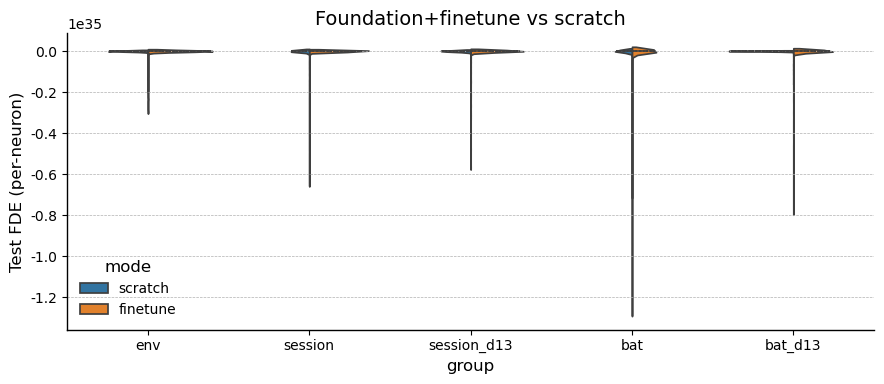

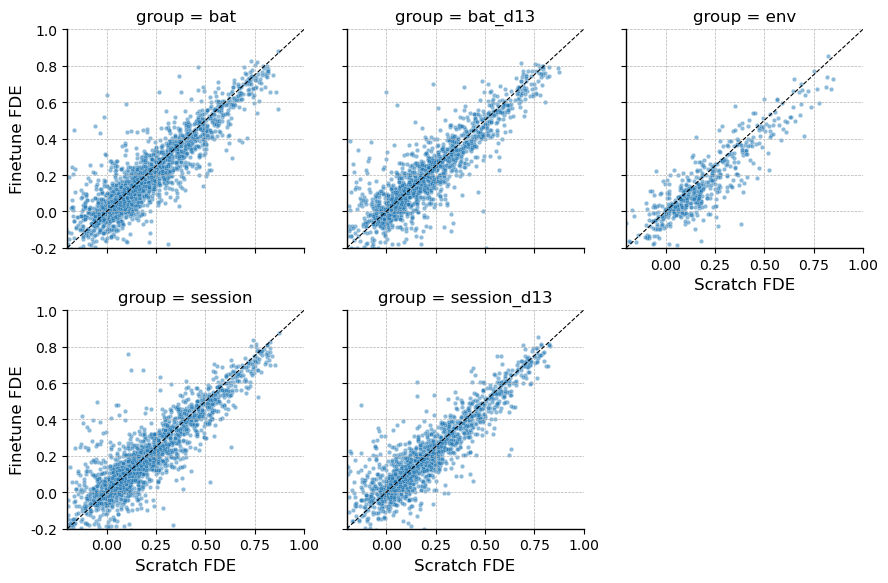

In [13]:
def load_all_results():
    dfs = []
    for g in ('env', 'session', 'session_d13', 'bat', 'bat_d13'):
        p = os.path.join(OUT_ROOT, g, f'results_{g}.pkl')
        if os.path.exists(p):
            dfs.append(pd.read_pickle(p))
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


df_all = load_all_results()
if not df_all.empty:
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.violinplot(data=df_all, x='group', y='fde', hue='mode', split=True, inner='quartile', ax=ax)
    ax.set_ylabel('Test FDE (per-neuron)')
    ax.set_title('Foundation+finetune vs scratch')
    plt.tight_layout()

    # paired scatter per group
    pivot = (df_all.pivot_table(index=['group', 'heldout', 'target_session', 'neuron_idx'],
                                 columns='mode', values='fde')
             .reset_index())
    pivot = pivot.dropna(subset=['finetune', 'scratch'])
    if not pivot.empty:
        g = sns.FacetGrid(pivot, col='group', col_wrap=3, height=3, sharex=True, sharey=True)
        g.map_dataframe(sns.scatterplot, x='scratch', y='finetune', alpha=0.5, s=10)
        for ax in g.axes.flat:
            lo, hi = -0.2, 1.0
            ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
            ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        g.set_axis_labels('Scratch FDE', 'Finetune FDE')
        plt.tight_layout()
else:
    print('No results on disk yet.')

# Paired statistics: finetune vs scratch

Paired comparisons at two aggregation levels:
1. **Neuron level** \u2014 pair `(target_session, neuron_idx)` across modes, test per-neuron FDE difference.
2. **Session level** \u2014 take median FDE across neurons within each target session, pair across modes.

Wilcoxon signed-rank is the primary test (non-parametric, robust to extreme FDE tails). Paired t on FDE clipped to [-1, 1] is included for magnitude intuition.

In [14]:
from scipy.stats import wilcoxon, ttest_rel


def paired_stats_neuron(df):
    """Per-neuron paired Finetune-vs-Scratch stats, broken down by group."""
    pair = (df.pivot_table(index=['group', 'heldout', 'target_session', 'neuron_idx'],
                            columns='mode', values='fde')
              .reset_index())
    pair = pair.dropna(subset=['finetune', 'scratch'])
    pair = pair[np.isfinite(pair['finetune']) & np.isfinite(pair['scratch'])]
    rows = []
    for group, sub in pair.groupby('group'):
        d = sub['finetune'] - sub['scratch']
        w2 = wilcoxon(d, alternative='two-sided')
        w_gt = wilcoxon(d, alternative='greater')  # H1: finetune > scratch
        t_clip = ttest_rel(sub['finetune'].clip(-1, 1), sub['scratch'].clip(-1, 1))
        rows.append(dict(
            group=group,
            n_neurons=len(sub),
            median_finetune=sub['finetune'].median(),
            median_scratch=sub['scratch'].median(),
            median_diff=d.median(),
            frac_finetune_wins=(d > 0).mean(),
            wilcoxon_W=w2.statistic,
            wilcoxon_p_two=w2.pvalue,
            wilcoxon_p_ft_gt=w_gt.pvalue,
            t_clip=t_clip.statistic,
            t_clip_p=t_clip.pvalue,
        ))
    return pd.DataFrame(rows)


def paired_stats_session(df):
    """Session-level paired stats: median FDE per target session, paired across modes."""
    sess = (df.groupby(['group', 'heldout', 'target_session', 'mode'])['fde']
              .median().unstack('mode').reset_index())
    sess = sess.dropna(subset=['finetune', 'scratch'])
    rows = []
    for group, sub in sess.groupby('group'):
        d = sub['finetune'] - sub['scratch']
        if len(sub) >= 1:
            try:
                w2 = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
                w_gt = wilcoxon(d, alternative='greater', zero_method='wilcox')
                wp2, wpgt, wW = w2.pvalue, w_gt.pvalue, w2.statistic
            except ValueError:
                wp2, wpgt, wW = np.nan, np.nan, np.nan
            t = ttest_rel(sub['finetune'], sub['scratch']) if len(sub) > 1 else None
        rows.append(dict(
            group=group,
            n_sessions=len(sub),
            mean_finetune=sub['finetune'].mean(),
            mean_scratch=sub['scratch'].mean(),
            mean_diff=d.mean(),
            frac_sessions_finetune_wins=(d > 0).mean(),
            wilcoxon_W=wW,
            wilcoxon_p_two=wp2,
            wilcoxon_p_ft_gt=wpgt,
            t_stat=(t.statistic if t is not None else np.nan),
            t_p=(t.pvalue if t is not None else np.nan),
        ))
    return pd.DataFrame(rows), sess


df_all = load_all_results()
if df_all.empty:
    print('No results on disk yet.')
else:
    neuron_stats = paired_stats_neuron(df_all)
    session_stats, session_table = paired_stats_session(df_all)
    print('=== Per-group neuron-level paired stats ===')
    display(neuron_stats.round(4))
    print()
    print('=== Per-group session-level paired stats ===')
    display(session_stats.round(4))
    print()
    print('=== Session medians (by group, heldout, target_session) ===')
    display(session_table.round(4))

=== Per-group neuron-level paired stats ===


,group,n_neurons,median_finetune,median_scratch,median_diff,frac_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_clip,t_clip_p
0,bat,2253,0.1212,0.1236,-0.0143,0.4217,1034986.0,0.0000,1.0000,-1.5201,0.1286
1,bat_d13,1695,0.1270,0.1304,-0.0118,0.4454,631526.0,0.0000,1.0000,-0.6544,0.5130
2,env,558,0.0969,0.1457,-0.0387,0.2939,38008.0,0.0000,1.0000,-9.7606,0.0000
3,session,2253,0.1228,0.1205,-0.0103,0.4350,1106645.5,0.0000,1.0000,-0.7717,0.4404
4,session_d13,1695,0.1358,0.1297,-0.0056,0.4608,688262.0,0.1312,0.9344,2.6594,0.0079



=== Per-group session-level paired stats ===


,group,n_sessions,mean_finetune,mean_scratch,mean_diff,frac_sessions_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_stat,t_p
0,bat,18,0.1571,0.1604,-0.0033,0.2222,53.0,0.1674,0.9230,-0.2901,0.7753
1,bat_d13,14,0.1649,0.1663,-0.0013,0.3571,46.0,0.7148,0.6651,-0.1175,0.9083
2,env,4,0.1157,0.1599,-0.0442,0.0000,0.0,0.1250,1.0000,-10.4636,0.0019
3,session,18,0.1553,0.1654,-0.0101,0.3889,50.0,0.1297,0.9406,-1.1525,0.2651
4,session_d13,14,0.1713,0.1637,0.0077,0.4286,52.0,1.0000,0.5242,0.4956,0.6285



=== Session medians (by group, heldout, target_session) ===


mode,group,heldout,target_session,finetune,scratch
0,bat,00000,Dataset_3_00000_240402,0.1484,0.1499
1,bat,00000,Dataset_3_00000_240403,0.2145,0.2363
2,bat,00000,Dataset_3_00000_240404,0.1604,0.1587
3,bat,00000,Dataset_3_00000_240405,0.1943,0.2386
4,bat,14445,Dataset_2_14445_231208,0.1180,0.1517
...,...,...,...,...,...
63,session_d13,Dataset_3_14543_240421,Dataset_3_14543_240421,0.2547,0.1949
64,session_d13,Dataset_3_29959_240402,Dataset_3_29959_240402,0.0727,0.0950
65,session_d13,Dataset_3_29959_240403,Dataset_3_29959_240403,0.1696,0.1740
66,session_d13,Dataset_3_29959_240404,Dataset_3_29959_240404,0.1561,0.1515


# Scaling with number of training sessions

For each universe (`SESSIONS` with 18, `SESSIONS_D13` with 14) we train end-to-end models on session counts $N \in \{2, 4, 8, N_\text{full}\}$ and compare against the $N=1$ scratch models already saved by the session sweeps. $N \in \{2,4,8\}$ uses **5 different random subsamples** of sessions per value; $N_\text{full}$ is deterministic (one model trained on the full universe). Each trained model scores one FDE value per included session (evaluated on that session's test split), so each target session appears in $\sim 5 \cdot N / N_\text{full}$ subsamples on average at $N \in \{2,4,8\}$.

In [ ]:
def stratified_subsamples(universe, N, n_samples, rng):
    """Draw n_samples size-N subsets from `universe` such that every session
    appears in at least one subset.

    Stage 1: round-robin anchors \u2014 sample i anchors universe[i % N_full] (shuffled order),
             remaining N-1 slots filled uniformly without replacement from the rest.
    Stage 2: coverage repair \u2014 for each session still uncovered, find a subset where we can
             swap it in for a session that appears in >= 1 other subset (so coverage never drops).
    """
    universe = list(universe)
    N_full = len(universe)
    assert N <= N_full

    anchors = list(universe)
    rng.shuffle(anchors)
    samples = []
    for i in range(n_samples):
        anchor = anchors[i % N_full]
        others_pool = [s for s in universe if s != anchor]
        rest = list(rng.choice(others_pool, size=N - 1, replace=False))
        samples.append(sorted([anchor] + rest))

    covered = set().union(*samples) if samples else set()
    missing = sorted(set(universe) - covered)

    for m in missing:
        best = None  # (subset_idx, slot_idx, count_elsewhere)
        for si, sub in enumerate(samples):
            if m in sub:
                continue
            for ji, s in enumerate(sub):
                count_elsewhere = sum(1 for oi, osub in enumerate(samples)
                                      if oi != si and s in osub)
                if count_elsewhere >= 1 and (best is None or count_elsewhere > best[2]):
                    best = (si, ji, count_elsewhere)
        if best is None:
            raise RuntimeError(f'Cannot insert missing session {m} without dropping coverage')
        si, ji, _ = best
        samples[si][ji] = m
        samples[si] = sorted(samples[si])

    # sanity
    assert set().union(*samples) == set(universe), 'coverage repair failed'
    return samples


def run_scaling_sweep(group_name, scratch_group_name, universe_sessions,
                       sizes=(2, 4, 8), n_samples=10, seed=SEED,
                       max_workers=MAX_WORKERS):
    """
    Scaling curve: train models on size-N subsets of `universe_sessions` (n_samples stratified
    subsamples each, guaranteed to cover every session) plus the full universe.
    Evaluate each trained readout on its own session's test split.
    N=1 baseline is read from the saved `scratch_group_name` scratch checkpoints (no retraining).
    """
    universe = list(universe_sessions)
    N_full = len(universe)
    out_dir = os.path.join(OUT_ROOT, f'scaling_{group_name}')
    os.makedirs(out_dir, exist_ok=True)
    rows = []

    # ---- N=1: reuse saved scratch checkpoints from the session sweep ----
    for t in universe:
        scratch_path = ckpt_path(scratch_group_name, t, suffix=f'__{t}_scratch')
        if not os.path.exists(scratch_path):
            print(f'  [scaling_{group_name}] MISSING scratch for {t}: {scratch_path}')
            continue
        model = build_bat_former({t: unit_num_dict[t]}, behavior_dim)
        model.load_state_dict(torch.load(scratch_path, map_location=DEVICE))
        model.to(DEVICE)
        fde, pc = eval_on_session(model, t, dataloaders, split='test')
        for i, (f, c) in enumerate(zip(fde, pc)):
            rows.append(dict(scaling_group=group_name, n_sessions=1, sample_id=0,
                             target_session=t, neuron_idx=i,
                             fde=float(f), corr=float(c)))

    # ---- build stratified (N, sample_id) -> session subset ----
    rng = np.random.default_rng(seed)
    subsamples = {}
    for N in sizes:
        subs = stratified_subsamples(universe, N, n_samples, rng)
        for sid, sub in enumerate(subs):
            subsamples[(N, sid)] = sub
    subsamples[(N_full, 0)] = list(universe)

    # ---- train each subset in parallel ----
    tasks = []
    for (N, sid), sub in subsamples.items():
        path = os.path.join(out_dir,
            f'bat_former_seed_{seed}_wd_{WD}_scaling_{group_name}_N{N}_s{sid}.pth')
        tid = f'SCAL:{group_name}:N{N}:s{sid}'
        tasks.append((tid, lambda src=list(sub), p=path: train_foundation(src, p, seed=seed)))
    results = run_tasks_parallel(tasks, max_workers=max_workers, label=f'scaling_{group_name}')

    # ---- evaluate every (model, readout) on that readout's own session ----
    for (N, sid), sub in subsamples.items():
        r = results.get(f'SCAL:{group_name}:N{N}:s{sid}')
        if r is None:
            continue
        _, model = r
        for t in sub:
            fde, pc = eval_on_session(model, t, dataloaders, split='test')
            for i, (f, c) in enumerate(zip(fde, pc)):
                rows.append(dict(scaling_group=group_name, n_sessions=N, sample_id=sid,
                                 target_session=t, neuron_idx=i,
                                 fde=float(f), corr=float(c)))

    df = pd.DataFrame(rows)
    df_path = os.path.join(out_dir, f'results_scaling_{group_name}.pkl')
    df.to_pickle(df_path)
    print(f'Saved {len(df)} rows to {df_path}')
    return df

In [ ]:
RUN_SCALING_SESSION = True  # 5*3 + 1 = 16 new foundation trainings over SESSIONS (18)

if RUN_SCALING_SESSION:
    df_scaling_session = run_scaling_sweep(
        group_name='session',
        scratch_group_name='session',
        universe_sessions=SESSIONS,
    )

In [ ]:
RUN_SCALING_SESSION_D13 = True  # 5*3 + 1 = 16 new foundation trainings over SESSIONS_D13 (14)

if RUN_SCALING_SESSION_D13:
    df_scaling_d13 = run_scaling_sweep(
        group_name='session_d13',
        scratch_group_name='session_d13',
        universe_sessions=SESSIONS_D13,
    )

## Scaling analysis: plots + paired stats

- **Curve**: per-session median FDE (across neurons) at each $N$, with each subsample contributing one point; overlaid mean per $N$.
- **Paired stats**: for each $N \in \{2,4,8,N_\text{full}\}$, compare per-session median FDE against the matching $N=1$ scratch value for the same target session. With 5 subsamples, a target session contributes up to 5 paired comparisons per $N$ (or 0 if it was never drawn); we use Wilcoxon signed-rank + paired t on those pairs.

=== Scaling paired stats (per target session; H1: N-model mean FDE > scratch FDE on same target) ===


,scaling_group,n_sessions,n_targets,mean_fde_N,mean_fde_scratch,mean_diff,frac_targets_N_better,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_N_better,t_stat,t_p
0,session,2,18,0.1674,0.1738,-0.0064,0.5000,75.0,0.6705,0.6802,-0.7899,0.4405
1,session,4,18,0.1673,0.1738,-0.0066,0.4444,62.0,0.3247,0.8481,-1.1187,0.2788
2,session,8,18,0.1695,0.1738,-0.0043,0.3889,69.0,0.4951,0.7659,-0.6481,0.5256
3,session,18,18,0.1605,0.1738,-0.0133,0.2778,48.0,0.1084,0.9506,-1.7877,0.0917
4,session_d13,2,14,0.1699,0.1652,0.0047,0.4286,46.0,0.7148,0.6651,0.3496,0.7323
5,session_d13,4,14,0.1782,0.1652,0.0130,0.4286,51.0,0.9515,0.5484,0.7919,0.4426
6,session_d13,8,14,0.1814,0.1652,0.0162,0.5000,52.0,1.0000,0.5242,0.9061,0.3814
7,session_d13,14,14,0.1809,0.1652,0.0157,0.4286,52.0,1.0000,0.5000,0.8177,0.4283


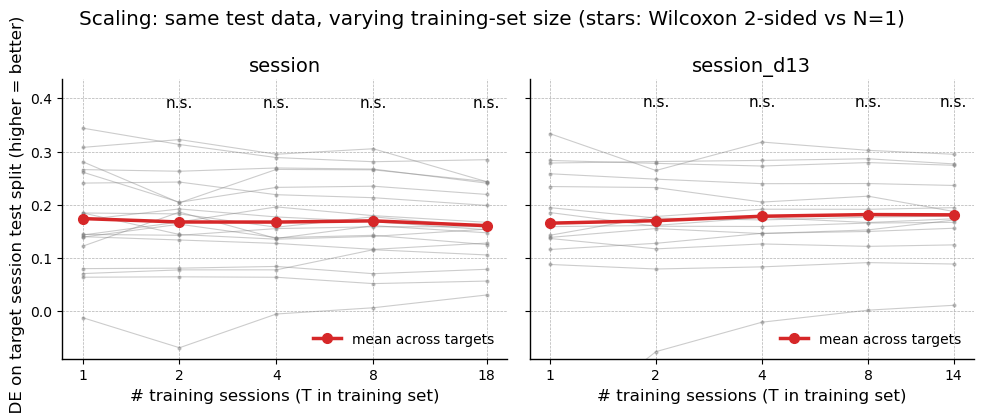

In [39]:
def load_scaling_results():
    dfs = []
    for g in ('session', 'session_d13'):
        p = os.path.join(OUT_ROOT, f'scaling_{g}', f'results_scaling_{g}.pkl')
        if os.path.exists(p):
            dfs.append(pd.read_pickle(p))
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


def scaling_per_target(df):
    """Median FDE across neurons per (group, N, sample_id, target), then mean over subsamples
    that contained the target. One FDE value per (group, N, target) \u2014 paired across N by target."""
    med = (df.groupby(['scaling_group', 'n_sessions', 'sample_id', 'target_session'])['fde']
             .median().reset_index(name='fde_median'))
    per_T = (med.groupby(['scaling_group', 'n_sessions', 'target_session'])['fde_median']
                .agg(['mean', 'count']).reset_index()
                .rename(columns={'mean': 'fde', 'count': 'n_subsamples'}))
    return per_T


def scaling_paired_stats(per_T):
    """Pair per-target FDE at N>1 vs N=1 scratch on the same target; Wilcoxon + paired t."""
    base = (per_T[per_T['n_sessions'] == 1]
            .set_index(['scaling_group', 'target_session'])['fde']
            .rename('fde_scratch'))
    rows = []
    for (grp, N), sub in per_T[per_T['n_sessions'] > 1].groupby(['scaling_group', 'n_sessions']):
        joined = sub.join(base, on=['scaling_group', 'target_session']).dropna(subset=['fde', 'fde_scratch'])
        d = joined['fde'] - joined['fde_scratch']
        try:
            w2 = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
            w_gt = wilcoxon(d, alternative='greater', zero_method='wilcox')
            wW, wp2, wpgt = w2.statistic, w2.pvalue, w_gt.pvalue
        except ValueError:
            wW = wp2 = wpgt = np.nan
        t = ttest_rel(joined['fde'], joined['fde_scratch']) if len(joined) > 1 else None
        rows.append(dict(
            scaling_group=grp, n_sessions=int(N),
            n_targets=len(joined),
            mean_fde_N=joined['fde'].mean(),
            mean_fde_scratch=joined['fde_scratch'].mean(),
            mean_diff=d.mean(),
            frac_targets_N_better=(d > 0).mean(),
            wilcoxon_W=wW, wilcoxon_p_two=wp2, wilcoxon_p_N_better=wpgt,
            t_stat=(t.statistic if t is not None else np.nan),
            t_p=(t.pvalue if t is not None else np.nan),
        ))
    return pd.DataFrame(rows)


def p_to_stars(p):
    if p is None or not np.isfinite(p):
        return ''
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'n.s.'


df_sc = load_scaling_results()
if df_sc.empty:
    print('No scaling results on disk yet. Flip RUN_SCALING_* flags and rerun.')
else:
    per_T = scaling_per_target(df_sc)
    stats = scaling_paired_stats(per_T)

    groups = sorted(per_T['scaling_group'].unique())
    fig, axes = plt.subplots(1, len(groups), figsize=(5 * len(groups), 4.2),
                              sharey=True, squeeze=False)
    for ax, grp in zip(axes[0], groups):
        sub = per_T[per_T['scaling_group'] == grp]
        ns = sorted(sub['n_sessions'].unique())
        wide = sub.pivot(index='target_session', columns='n_sessions', values='fde').reindex(columns=ns)
        for _, row in wide.iterrows():
            ax.plot(ns, row.values, color='gray', alpha=0.4, lw=0.8, marker='.', ms=4)
        means = [sub[sub['n_sessions'] == n]['fde'].mean() for n in ns]
        ax.plot(ns, means, color='C3', lw=2.5, marker='o', ms=7, label='mean across targets')

        # Star annotations for each N>1 vs N=1 (two-sided Wilcoxon p)
        y_top = sub['fde'].max()
        y_bot = sub['fde'].min()
        y_txt = y_top + 0.08 * (y_top - y_bot)
        gs = stats[stats['scaling_group'] == grp].set_index('n_sessions')
        for n in ns:
            if n == 1:
                continue
            p = gs.loc[n, 'wilcoxon_p_two'] if n in gs.index else np.nan
            ax.text(n, y_txt, p_to_stars(p), ha='center', va='bottom', fontsize=11)
        ax.set_ylim(top=y_top + 0.18 * (y_top - y_bot))

        ax.set_xscale('log', base=2)
        ax.set_xticks(ns); ax.set_xticklabels(ns)
        ax.set_xlabel('# training sessions (T in training set)')
        ax.set_title(grp)
        ax.legend(frameon=False, loc='lower right')
    axes[0, 0].set_ylabel('FDE on target session test split (higher = better)')
    fig.suptitle('Scaling: same test data, varying training-set size (stars: Wilcoxon 2-sided vs N=1)')
    plt.tight_layout()

    print('=== Scaling paired stats (per target session; H1: N-model mean FDE > scratch FDE on same target) ===')
    display(stats.round(4))